# Assignment 4 — One- and Two-Sample Tests

**Course:** STA1

**Group members:** Bibek Paudel, Dora Buruncuk, Supendra Bogati

## Table of contents
1. [Part 1 — One-sample decisions](#part1)
2. [Part 2 — Independent coating processes](#part2)
3. [Part 3 — Paired building-energy measurements](#part3)
4. [Part 4 — Comparing two independent proportions](#part4)
5. [Part 5 — AI-use and conclusion](#part5)

In [6]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t, ttest_rel, ttest_1samp, ttest_ind, shapiro, probplot, skew

DATA = "data/"

energy = pd.read_csv(DATA + "assignment04_energy_retrofit.csv")   # Part 3

print(f"energy: {energy.shape[0]} rows x {energy.shape[1]} columns")

energy: 36 rows x 3 columns


<a id="part3"></a>
# Part 3 — Paired building-energy measurements

> The file assignment04_energy_retrofit.csv records energy use for the same 36 buildings before and
> after a control-system retrofit. Define the paired difference
> $$D_i = \text{before}_i - \text{after}_i,$$
> so a positive value represents a reduction.

**Population:** all buildings of this kind that could receive the control-system retrofit.

**Parameter:** $\mu_D$, the population mean reduction in daily energy use in kWh/day, where
$D = \text{before} - \text{after}$. A positive $\mu_D$ means energy use goes down.

**Observational unit:** one building, measured before and after the retrofit.

**Design:** paired, 36 buildings each measured twice. The comparison order before $-$ after is fixed
before the analysis, and the pairs are analysed as one sample of 36 differences.

**Assumptions:** buildings independent of each other and representative, and differences close to
normal (or $n$ large enough for $\bar D$ to be close to normal).

## a)

> Explain the observational unit and why the rows form genuine pairs. Create the difference column
> and report its mean, standard deviation, and standard error.

**Why genuine pairs:** both values in a row come from the same building, so they share its size,
use and occupants (Definition 8.2). The two values in a row are dependent; different buildings are
independent. The analysis uses $n = 36$ pairs, not 72 observations (Section 8.3).

$$D_i = \text{before}_i - \text{after}_i, \qquad \widehat{\text{SE}}(\bar D) = \frac{s_D}{\sqrt n}$$

In [7]:
energy["diff_kwh_day"] = energy["before_kwh_day"] - energy["after_kwh_day"]   # positive = reduction
before = energy["before_kwh_day"].to_numpy()
after = energy["after_kwh_day"].to_numpy()
d = energy["diff_kwh_day"].to_numpy()

n = d.size
d_bar = d.mean()
s_d = d.std(ddof=1)     # SD of the differences
se_d = s_d / np.sqrt(n)  # estimated standard error of the mean difference

print(energy.head().round(2))
print()
print("unique building IDs:", energy["building_id"].is_unique)   # data audit
print("missing values:", int(energy.isna().sum().sum()))
print()
print(f"n    = {n} buildings")
print(f"dbar = {d_bar:.4f} kWh/day")
print(f"s_D  = {s_d:.4f} kWh/day")
print(f"SE   = s_D / sqrt(n) = {s_d:.4f} / {np.sqrt(n):.0f} = {se_d:.4f} kWh/day")
print(f"buildings with higher use after the retrofit (d < 0): {np.sum(d < 0)} of {n}")

   building_id  before_kwh_day  after_kwh_day  diff_kwh_day
0            1           91.57          87.75          3.82
1            2           95.33          90.14          5.19
2            3           85.20          85.61         -0.41
3            4           75.96          64.30         11.66
4            5           85.33          81.90          3.43

unique building IDs: True
missing values: 0

n    = 36 buildings
dbar = 4.8228 kWh/day
s_D  = 4.5036 kWh/day
SE   = s_D / sqrt(n) = 4.5036 / 6 = 0.7506 kWh/day
buildings with higher use after the retrofit (d < 0): 6 of 36


**Audit:** each building appears once, no values are missing, and both columns are daily energy use
in kWh/day for the same building, so all 36 pairs are complete and comparable.

**Summary:** the mean reduction is $\bar d = 4.82$ kWh/day, with $s_D = 4.50$ kWh/day and
SE $= 0.75$ kWh/day. 30 of the 36 buildings used less energy after the retrofit.

## b)

> Plot the paired values and the distribution or QQ-plot of differences. Diagnose the
> differences—not the two raw columns separately—for the paired procedure.

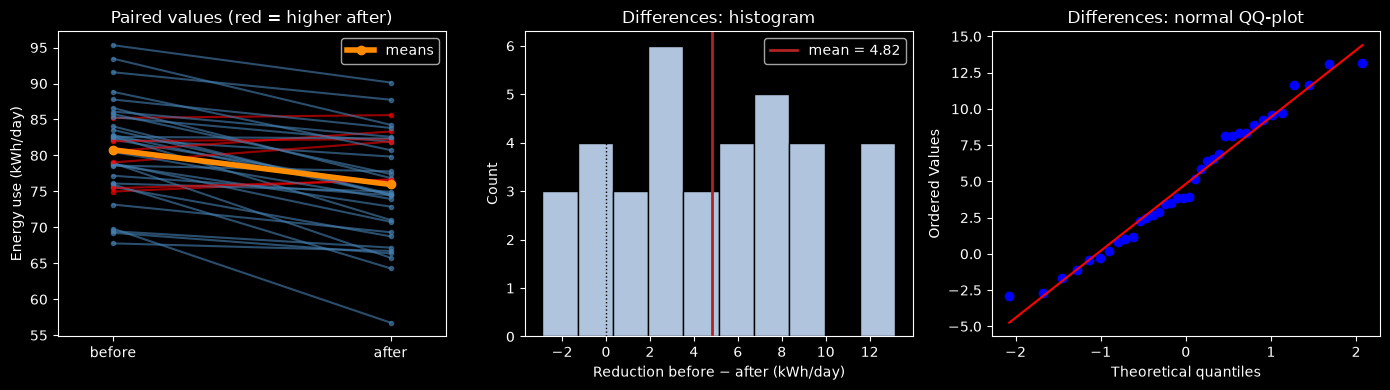

Shapiro–Wilk on the differences: W = 0.969, p = 0.403
skewness of the differences: 0.11
outliers among the differences (1.5xIQR rule): []


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for b, a in zip(before, after):   # one line per building
    axes[0].plot([0, 1], [b, a], color="red" if a > b else "steelblue", alpha=0.6, marker="o", ms=3)
axes[0].plot([0, 1], [before.mean(), after.mean()], color="darkorange", lw=4, marker="o", label="means")
axes[0].legend()
axes[0].set(xticks=[0, 1], xticklabels=["before", "after"], xlim=(-0.2, 1.2),
            ylabel="Energy use (kWh/day)", title="Paired values (red = higher after)")

axes[1].hist(d, bins=10, color="lightsteelblue", edgecolor="black")
axes[1].axvline(0, color="black", ls=":", lw=1)
axes[1].axvline(d_bar, color="firebrick", lw=2, label=f"mean = {d_bar:.2f}")
axes[1].set(title="Differences: histogram", xlabel="Reduction before − after (kWh/day)", ylabel="Count")
axes[1].legend()

probplot(d, dist="norm", plot=axes[2])
axes[2].set_title("Differences: normal QQ-plot")

fig.tight_layout()
plt.show()

W, p_sw = shapiro(d)
q1, q3 = np.percentile(d, [25, 75])
iqr = q3 - q1
outliers = d[(d < q1 - 1.5 * iqr) | (d > q3 + 1.5 * iqr)]
print(f"Shapiro–Wilk on the differences: W = {W:.3f}, p = {p_sw:.3f}")
print(f"skewness of the differences: {skew(d):.2f}")
print(f"outliers among the differences (1.5xIQR rule): {outliers}")

**Assumption check:** the paired test is a one-sample $t$ test on the differences, so the
differences are checked, not the two columns. The histogram is roughly symmetric (skewness 0.11)
with no outliers, the QQ points follow the line, and Shapiro–Wilk ($p = 0.403$) gives no evidence
against normality, so the $t$ procedure is reasonable. These checks cannot show independence; that
depends on how the buildings were selected.

## c)

> Test $H_0:\mu_D=0$ against a two-sided alternative and construct a 95% interval for $\mu_D$, using
> `ttest_rel` or an equivalent one-sample procedure applied to the differences.

$$H_0: \mu_D = 0 \qquad H_1: \mu_D \ne 0 \qquad \alpha = 0.05$$

One-sample $t$ test on the differences (Theorem 8.2), $n$ = number of pairs:

$$t_{\text{obs}} = \frac{\bar d}{s_D/\sqrt n}, \qquad \text{df} = n - 1, \qquad
\bar d \pm t_{n-1,\,0.975}\,\frac{s_D}{\sqrt n}$$

In [9]:
alpha = 0.05

df = n - 1
t_obs = (d_bar - 0) / se_d
p_two = 2 * t.sf(abs(t_obs), df)

t_crit = t.ppf(0.975, df)
me = t_crit * se_d
ci_lo, ci_hi = d_bar - me, d_bar + me

res_rel = ttest_rel(before, after)                # paired test, order: before - after
res_one = ttest_1samp(d, popmean=0)               # same test as one sample of differences
ci_rel = res_rel.confidence_interval(0.95)

print(f"dbar               = {d_bar:.4f} kWh/day")
print(f"SE                 = {se_d:.4f} kWh/day")
print(f"t                  = {d_bar:.4f} / {se_d:.4f} = {t_obs:.3f}")
print(f"degrees of freedom = {n} - 1 = {df}")
print(f"two-sided p        = {p_two:.2e}")
print(f"critical value     = {t_crit:.4f}")
print(f"margin of error    = {t_crit:.4f} * {se_d:.4f} = {me:.4f} kWh/day")
print(f"95% CI for mu_D    = [{ci_lo:.4f}, {ci_hi:.4f}] kWh/day")
print()
print(f"ttest_rel   check: t = {res_rel.statistic:.3f}, df = {res_rel.df}, p = {res_rel.pvalue:.2e}, "
      f"CI = [{ci_rel.low:.4f}, {ci_rel.high:.4f}]")
print(f"ttest_1samp check: t = {res_one.statistic:.3f}, df = {res_one.df}, p = {res_one.pvalue:.2e}")
print(f"decision at alpha = {alpha}:", "reject H0" if p_two < alpha else "fail to reject H0")

dbar               = 4.8228 kWh/day
SE                 = 0.7506 kWh/day
t                  = 4.8228 / 0.7506 = 6.425
degrees of freedom = 36 - 1 = 35
two-sided p        = 2.14e-07
critical value     = 2.0301
margin of error    = 2.0301 * 0.7506 = 1.5238 kWh/day
95% CI for mu_D    = [3.2990, 6.3466] kWh/day

ttest_rel   check: t = 6.425, df = 35, p = 2.14e-07, CI = [3.2990, 6.3466]
ttest_1samp check: t = 6.425, df = 35, p = 2.14e-07
decision at alpha = 0.05: reject H0


**Result:** the estimated mean reduction is $\bar d = 4.82$ kWh/day, with 95 % interval
$[3.30,\ 6.35]$ kWh/day for $\mu_D$. The test gives $t = 6.43$ on 35 df and two-sided
$p = 2.1 \times 10^{-7}$. `ttest_rel` gives the same values.

**$p$-value:** if $\mu_D = 0$ and the assumptions hold, a $t$ statistic at least as far from 0 as
6.43, in either direction, would occur with probability about $2 \times 10^{-7}$. It is not the
probability that $H_0$ is true.

**Decision:** $p = 2.1 \times 10^{-7} < 0.05$, so we reject $H_0$. This matches the interval,
which lies above 0.

**Conclusion:** the data give evidence that mean daily energy use was lower after the retrofit, for
buildings represented by this study. The estimated reduction is 4.82 kWh/day, with plausible values
from about 3.3 to 6.3 kWh/day.

## d)

> Explain why an independent-samples test would discard useful pairing. Interpret the estimated
> reduction and interval in kWh/day and state a practical recommendation.

Welch's test is run for comparison only. It treats before and after as independent, so it leaves
out the correlation term:

$$\operatorname{Var}(D) = \sigma_{\text{before}}^2 + \sigma_{\text{after}}^2
- 2\rho\,\sigma_{\text{before}}\,\sigma_{\text{after}}$$

In [10]:
s_before, s_after = before.std(ddof=1), after.std(ddof=1)
r = np.corrcoef(before, after)[0, 1]   # how strongly a building's before and after values move together

se_welch = np.sqrt(s_before**2 / n + s_after**2 / n)
res_ind = ttest_ind(before, after, equal_var=False)   # wrong design, for comparison only
ci_ind = res_ind.confidence_interval(0.95)

comparison = pd.DataFrame({
    "SE": [se_d, se_welch],
    "t": [res_rel.statistic, res_ind.statistic],
    "df": [res_rel.df, res_ind.df],
    "p-value": [res_rel.pvalue, res_ind.pvalue],
    "CI lower": [ci_lo, ci_ind.low],
    "CI upper": [ci_hi, ci_ind.high],
    "CI width": [ci_hi - ci_lo, ci_ind.high - ci_ind.low],
}, index=["paired (correct)", "Welch (ignores pairing)"])

print(f"s_before = {s_before:.3f}, s_after = {s_after:.3f}, s_D = {s_d:.3f} kWh/day")
print(f"correlation r between before and after = {r:.3f}")
print(f"SE from the formula with r = {np.sqrt((s_before**2 + s_after**2 - 2*r*s_before*s_after) / n):.4f} kWh/day")
print()
print(comparison.to_string(float_format="{:.4f}".format, formatters={"p-value": "{:.2e}".format}))
print()
print(f"reduction as % of mean 'before' use: {d_bar / before.mean():.1%} "
      f"(CI {ci_lo / before.mean():.1%} to {ci_hi / before.mean():.1%})")
print(f"reduction per building per year: {d_bar * 365:.0f} kWh "
      f"(CI {ci_lo * 365:.0f} to {ci_hi * 365:.0f} kWh)")

s_before = 6.634, s_after = 7.353, s_D = 4.504 kWh/day
correlation r between before and after = 0.797
SE from the formula with r = 0.7506 kWh/day

                            SE      t      df  p-value  CI lower  CI upper  CI width
paired (correct)        0.7506 6.4252 35.0000 2.14e-07    3.2990    6.3466    3.0476
Welch (ignores pairing) 1.6505 2.9220 69.2707 4.69e-03    1.5303    8.1152    6.5849

reduction as % of mean 'before' use: 6.0% (CI 4.1% to 7.9%)
reduction per building per year: 1760 kWh (CI 1204 to 2317 kWh)


**Why pairing matters:** before and after are strongly correlated ($r = 0.80$), because large
buildings use a lot of energy in both periods. Each building acts as its own comparison, so pairing
removes this building-to-building variation. As a result, the paired SE is 0.75 kWh/day against
1.65 kWh/day for Welch, and the interval is less than half as wide
($[3.30,\ 6.35]$ vs $[1.53,\ 8.12]$ kWh/day).

**Interpretation:** mean energy use fell by an estimated 4.82 kWh/day per building, with a 95 %
interval from 3.30 to 6.35 kWh/day. That is about 6 %, or 1,760 kWh per building per year. This is a
mean effect: it does not mean every building saves energy, and 6 of the 36 used slightly more.

**Recommendation:** the whole interval lies above 0, so the data clearly support a lower mean energy
use after the retrofit. The retrofit is worth rolling out to similar buildings if the saving at the
lower end of the interval, 3.3 kWh/day, covers its cost, preferably in stages with continued
monitoring of energy use.

**Limitation:** there is no control group, so changes in weather, season or occupancy between the
two periods are mixed in with the retrofit effect. The data show a reduction after the retrofit, but
cannot prove that the retrofit alone caused it. Cost, comfort and reliability need separate
evidence.